# Notebook A: dữ liệu, làm sạch, SQL và hình RQ1

**Đề tài:** Dự báo trước một ngày điện tiêu thụ toàn quốc của Thổ Nhĩ Kỳ giữ được độ chính xác vào ngày lễ và ở các năm sau

**Sinh viên A** chạy lần lượt từ trên xuống. Mỗi ô code có một ô hướng dẫn ngay phía trên gồm ba ý: làm gì, vì sao, kiểm tra gì. Sản phẩm bàn giao cho Notebook B là file parquet trong `data/processed/`, file `sql/queries.sql` và `data/processed/manifest.json`.

## Bước 0. Môi trường

- **Làm gì:** cài thư viện (một lần), tạo thư mục, nạp ba hàm tiện ích.
- **Vì sao:** hai notebook của nhóm dùng chung cấu trúc thư mục để bàn giao file cho nhau.
- **Kiểm tra:** ô chạy xong không báo lỗi.

In [1]:
# run once per machine, then comment out
# %pip install pandas numpy duckdb pyarrow scikit-learn lightgbm xgboost matplotlib scipy

In [2]:
import os, glob, zipfile, urllib.request
for d in ['data/raw', 'data/processed', 'report', 'sql']: os.makedirs(d, exist_ok=True)
def fetch(url, name):                                   # download once into data/raw
    path = 'data/raw/' + name
    os.makedirs(os.path.dirname(path), exist_ok=True)
    if not os.path.exists(path): print('downloading', url); urllib.request.urlretrieve(url, path)
    return path
def unzip_all(folder='data/raw'):                       # unpack archives, including archives inside archives
    done = set()
    while True:
        todo = [z for z in glob.glob(folder + '/**/*.zip', recursive=True) if z not in done]
        if not todo: break
        for z in todo:
            with zipfile.ZipFile(z) as f: f.extractall(os.path.dirname(z))
            done.add(z)
def find1(name):                                        # locate one file wherever the archive put it
    hits = glob.glob('data/raw/**/' + name, recursive=True); assert hits, 'not found: ' + name; return hits[0]

## Bước 1a. Tải dữ liệu

- **Làm gì:** tải file gốc về `data/raw/` và giải nén. Ô này bỏ qua nếu dữ liệu đã có.
- **Vì sao:** người khác chạy lại notebook phải nhận đúng cùng một bộ dữ liệu.
- **Kiểm tra:** ô in đường dẫn của từng file cần có. Nếu tải tự động lỗi hoặc thiếu file, tải tay tại `github.com/KeremReyhani/Predicting-Electricity-Prices-and-Consumption (file birlesik_veri.csv)`, chép vào `data/raw/` rồi chạy lại ô này.

In [3]:
FILES = [('https://raw.githubusercontent.com/KeremReyhani/Predicting-Electricity-Prices-and-Consumption/main/birlesik_veri.csv', 'birlesik_veri.csv')]
NEED = ['birlesik_veri.csv']
have = lambda: [glob.glob('data/raw/**/' + n, recursive=True) for n in NEED]
if not all(have()):
    for url, name in FILES:
        try: fetch(url, name)
        except Exception as e: print('download failed:', name, e)
    unzip_all()
for n, hit in zip(NEED, have()):
    assert hit, 'missing ' + n + ': download by hand from github.com/KeremReyhani/Predicting-Electricity-Prices-and-Consumption (file birlesik_veri.csv) into data/raw and run this cell again'
    print(n, '->', hit[0], os.path.getsize(hit[0]) // 1024, 'kB')

birlesik_veri.csv -> data/raw\birlesik_veri.csv 4019 kB


## Bước 1b. Nạp dữ liệu

- **Làm gì:** đọc file gốc, tạo bảng làm việc.
- **Vì sao:** mọi bước sau dùng bảng này, nên số dòng và số cột in ra ở đây là con số ghi vào mục Data của bài.
- **Kiểm tra:** so số dòng, số cột với mô tả của bộ dữ liệu trong đề cương; nếu khác thì ghi lại con số thật.

In [4]:
# Step 1b: hourly electricity of Türkiye from 2021 to 2025: national generation, consumption and price in the format of the EPİAŞ Transparency Platform, joined with weather, 43,824 rows, 17 columns
# download (one csv, 4 MB, no account): https://raw.githubusercontent.com/KeremReyhani/Predicting-Electricity-Prices-and-Consumption/main/birlesik_veri.csv  (original source of the three market series: seffaflik.epias.com.tr)
import pandas as pd, numpy as np, glob
raw = pd.read_csv(glob.glob('data/raw/**/birlesik_veri.csv', recursive=True)[0], parse_dates=['Datetime']); print(raw.shape, raw.Datetime.min(), raw.Datetime.max())
print(raw.groupby(raw.Datetime.dt.year)[['tuketim_mwh', 'uretim_mwh', 'fiyat_tl', 'sicaklik']].mean().round(1))

(43824, 17) 2021-01-01 00:00:00 2025-12-31 23:00:00
          tuketim_mwh  uretim_mwh  fiyat_tl  sicaklik
Datetime                                             
2021          37305.3     35922.8     505.9      15.3
2022          36964.5     35535.7    2488.8      15.1
2023          37023.2     35309.2    2157.0      16.0
2024          39012.7     36567.4    2209.9      16.3
2025          40240.8     36812.7    2603.4      16.1


## Bước 2. Làm sạch có nhật ký

- **Làm gì:** kiểm tra miền giá trị, loại dòng lỗi, lưu parquet và nhật ký làm sạch.
- **Vì sao:** phản biện sẽ hỏi vì sao số dòng khác tài liệu gốc; nhật ký là câu trả lời.
- **Kiểm tra:** mở `report/table_cleaning_log.csv`, mỗi dòng bị bỏ phải có lý do.

In [5]:
# Step 2: English column names, check of the hourly grid, missing values and repeated hours, ten meaningful columns kept, cleaning log
log = [['raw rows', len(raw)]]
NAMES = {'Datetime': 'time', 'tuketim_mwh': 'consumption', 'uretim_mwh': 'generation', 'fiyat_tl': 'price_tl', 'sicaklik': 'temperature', 'hissedilen_sicaklik': 'feels_like', 'nem': 'humidity', 'bulut_ortus': 'cloud', 'ruzgar_hizi': 'wind', 'yagis': 'rain', 'is_holiday': 'holiday'}
df = raw.rename(columns=NAMES)[list(NAMES.values())].sort_values('time').drop_duplicates('time'); log.append(['after removing repeated hours', len(df)])
step = df.time.diff().dt.total_seconds().div(3600).dropna(); log += [['steps that are not one hour', int((step != 1).sum())], ['missing values', int(df.isna().sum().sum())], ['hours with consumption of zero or below', int((df.consumption <= 0).sum())]]
df['year'] = df.time.dt.year; df['month'] = df.time.dt.month; df['hour'] = df.time.dt.hour; df['dow'] = df.time.dt.dayofweek; df['weekend'] = (df.dow >= 5).astype(int)
for y in range(2021, 2026): g = df[df.year == y]; log.append(['%d: mean and peak consumption (MWh), holiday hours' % y, '%.0f, %.0f, %d' % (g.consumption.mean(), g.consumption.max(), g.holiday.sum())])
pd.DataFrame(log, columns=['step', 'value']).to_csv('report/table_cleaning_log.csv', index=False); print(log)
df.to_parquet('data/processed/electricity.parquet', index=False); print(df.shape)

[['raw rows', 43824], ['after removing repeated hours', 43824], ['steps that are not one hour', 0], ['missing values', 0], ['hours with consumption of zero or below', 0], ['2021: mean and peak consumption (MWh), holiday hours', '37305, 55575, 336'], ['2022: mean and peak consumption (MWh), holiday hours', '36965, 51354, 336'], ['2023: mean and peak consumption (MWh), holiday hours', '37023, 54045, 312'], ['2024: mean and peak consumption (MWh), holiday hours', '39013, 57772, 336'], ['2025: mean and peak consumption (MWh), holiday hours', '40241, 59504, 336']]
(43824, 16)


## Bước 2b. Hiểu dữ liệu trước khi đặt câu hỏi

Mười ô dưới đây đọc lại bảng đã làm sạch và trả lời lần lượt: bảng có những cột gì, phân phối ra sao, thiếu ở đâu, có giá trị lạ không, cột nào liên quan tới mục tiêu và mục tiêu khác nhau thế nào giữa các nhóm. **Quy tắc:** sau mỗi ô, nhóm viết một câu nhận xét có số vào dòng Nhận xét. Hình và mô hình chỉ tốt khi nhóm hiểu dữ liệu ở bước này.

### 2b.1 Nạp bảng sạch và xem năm dòng đầu

- **Làm gì:** đọc file parquet, chọn cột mục tiêu và cột nhóm, lấy mẫu cố định để vẽ nhanh.
- **Kiểm tra:** số dòng khớp với nhật ký làm sạch.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** sản xuất khá khớp với tiêu thụ, sản xuất, tiêu thụ, giá thay đổi mạnh theo thời điểm trong ngày, nhiệt độ cảm nhận thấp hơn tầm 3 độ so với nhiệt độ thực tế 

In [6]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
def nice(v, label):                                     # readable numbers on the bars
    v = np.asarray(v, dtype=float); m = np.nanmax(np.abs(v))
    return (v / 1e6, label + ' (million)', '{:.2f}') if m >= 1e6 else (v / 1e3, label + ' (thousand)', '{:.1f}') if m >= 1e4 else (v, label, '{:.2f}' if m < 100 else '{:.0f}')
E = pd.read_parquet('data/processed/electricity.parquet'); TGT, GRP = 'consumption', 'year'
S = E.sample(min(len(E), 50_000), random_state=0)          # a fixed sample keeps every plot fast
NUM = [c for c in S.select_dtypes('number').columns if c != 'row_id' and S[c].nunique() > 1]
print(E.shape[0], 'rows,', E.shape[1], 'columns;', len(NUM), 'numeric columns; target:', TGT, '; group:', GRP); display(E.head(5))

43824 rows, 16 columns; 15 numeric columns; target: consumption ; group: year


,time,consumption,generation,price_tl,temperature,feels_like,humidity,cloud,wind,rain,holiday,year,month,hour,dow,weekend
0,2021-01-01 00:00:00,29489.46,29488.11,259.39,9.79,6.91,77.41,59.42,13.50,0.01,1,2021,1,0,4,0
1,2021-01-01 01:00:00,28067.11,28065.76,234.13,9.88,6.58,75.14,34.92,15.98,0.01,1,2021,1,1,4,0
2,2021-01-01 02:00:00,26527.08,26527.08,215.25,9.58,6.37,77.43,37.49,15.81,0.01,1,2021,1,2,4,0
3,2021-01-01 03:00:00,25327.19,25327.19,219.24,9.55,6.26,78.35,41.92,16.13,0.01,1,2021,1,3,4,0
4,2021-01-01 04:00:00,24719.72,24719.72,209.81,9.32,6.26,79.02,36.95,14.82,0.06,1,2021,1,4,4,0


### 2b.2 Từ điển dữ liệu

- **Làm gì:** kiểu dữ liệu, tỷ lệ thiếu, số giá trị khác nhau và một ví dụ của từng cột.
- **Vì sao:** bảng này đi thẳng vào mục Data của bài (số dòng, số cột, ý nghĩa cột).
- **Kiểm tra:** cột nào chỉ có một giá trị hoặc thiếu trên 30% thì ghi lại và cân nhắc bỏ.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** dữ liệu đầy đủ 100%

In [7]:
dic = pd.DataFrame({'dtype': E.dtypes.astype(str), 'missing_pct': (100 * E.isna().mean()).round(2), 'unique': E.nunique(),
                    'example': E.iloc[0].astype(str).str.slice(0, 40)})
dic.to_csv('report/table_data_dictionary.csv'); display(dic)

,dtype,missing_pct,unique,example
time,datetime64[ns],0.0,43824,2021-01-01 00:00:00
consumption,float64,0.0,43420,29489.46
generation,float64,0.0,43343,29488.11
price_tl,float64,0.0,40831,259.39
temperature,float64,0.0,3781,9.79
feels_like,float64,0.0,4322,6.91
humidity,float64,0.0,6581,77.41
cloud,float64,0.0,9724,59.42
wind,float64,0.0,2432,13.5
rain,float64,0.0,281,0.01


### 2b.3 Thống kê mô tả các cột số

- **Làm gì:** trung bình, độ lệch chuẩn, các phân vị 1%, 50%, 99%, độ lệch (skew) và tỷ lệ giá trị bằng không.
- **Vì sao:** cột lệch mạnh cần biến đổi log hoặc cắt đuôi trước khi vẽ và trước khi đưa vào mô hình tuyến tính.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [8]:
num = S[NUM].describe(percentiles=[.01, .25, .5, .75, .99]).T; num['skew'] = S[NUM].skew()
num['zero_pct'] = (100 * (S[NUM] == 0).mean()).round(1); num.to_csv('report/table_numeric_summary.csv'); display(num.round(3))

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew,zero_pct
consumption,43824.0,38109.805,6197.273,19209.20,25808.844,33159.210,38256.175,42236.972,53430.326,59503.67,0.223,0.0
generation,43824.0,36029.874,5759.316,11175.31,22315.128,31852.378,35887.015,39974.978,49632.467,56219.06,0.045,0.0
price_tl,43824.0,1993.136,1090.176,0.74,123.475,1107.820,2131.720,2734.610,4713.272,4905.50,0.033,0.0
temperature,43824.0,15.772,8.250,-5.68,-0.220,9.240,15.220,22.170,32.968,38.42,0.148,0.0
feels_like,43824.0,14.252,9.695,-9.73,-4.808,6.530,13.560,22.330,33.698,39.20,0.090,0.0
humidity,43824.0,67.141,15.415,14.99,29.600,56.488,69.875,79.280,91.718,97.09,-0.555,0.0
cloud,43824.0,42.503,31.608,0.00,0.000,11.890,40.090,70.792,99.460,100.00,0.206,1.7
wind,43824.0,11.532,4.610,1.36,3.760,8.010,10.810,14.490,23.878,37.44,0.673,0.0
rain,43824.0,0.077,0.251,0.00,0.000,0.000,0.000,0.050,1.150,7.87,8.692,59.9
holiday,43824.0,0.038,0.191,0.00,0.000,0.000,0.000,0.000,1.000,1.00,4.848,96.2


### 2b.4 Giá trị thiếu và dòng trùng

- **Làm gì:** vẽ tỷ lệ thiếu của các cột còn thiếu và đếm dòng trùng.
- **Kiểm tra:** mỗi cột còn thiếu phải có cách xử lý ghi trong nhật ký làm sạch.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [9]:
miss = (100 * E.isna().mean()).sort_values(ascending=False); miss = miss[miss > 0].head(12)
print('duplicated rows:', int(S.duplicated().sum()), 'of', len(S), 'sampled rows')
if len(miss): bar_chart(miss.index, miss.values, 'Missing values (%)', 'report/fig_eda_missing.png', highlight=0, fmt='{:.1f}')
else: print('no missing values in the cleaned table')

duplicated rows: 0 of 43824 sampled rows
no missing values in the cleaned table


### 2b.5 Phân phối của mục tiêu

- **Làm gì:** vẽ phân phối cột mục tiêu, thêm thang log nếu là số liên tục, hoặc tỷ lệ từng lớp nếu là nhãn.
- **Vì sao:** lớp hiếm thì dùng PR-AUC thay accuracy; mục tiêu lệch thì báo thêm sai số tương đối.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

{'count': 43824.0, 'mean': 38109.805, 'std': 6197.273, 'min': 19209.2, '5%': 28840.766, '50%': 38256.175, '95%': 48763.261, 'max': 59503.67}


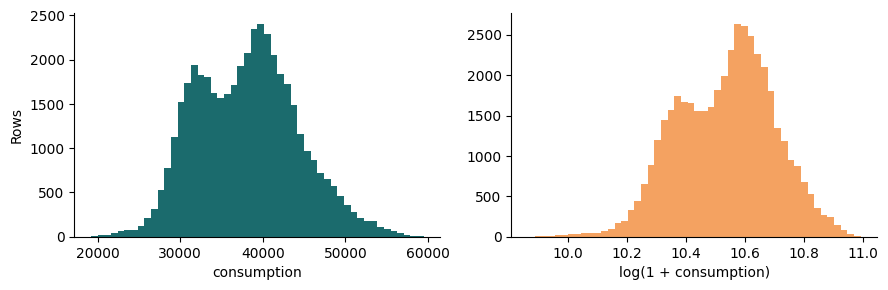

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3)); y = S[TGT].dropna().astype(float)
if y.nunique() <= 10:
    v = y.value_counts(normalize=True).sort_index() * 100; b = ax[0].bar(v.index.astype(str), v.values, color='#1B6B6D'); ax[0].bar_label(b, labels=['%.1f' % x for x in v.values], fontweight='bold'); ax[0].set_ylabel('Share of rows (%)')
    ax[1].axis('off'); print('class counts in the full table:', E[TGT].value_counts().to_dict())
else:
    ax[0].hist(y, bins=50, color='#1B6B6D'); ax[0].set_ylabel('Rows'); ax[0].set_xlabel(TGT)
    ax[1].hist(np.log1p(y.clip(lower=0)), bins=50, color='#F4A261'); ax[1].set_xlabel('log(1 + ' + TGT + ')')
    print(y.describe(percentiles=[.05, .5, .95]).round(3).to_dict())
for a in ax: a.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig('report/fig_eda_target.png', dpi=200); plt.show()

### 2b.6 Phân phối các cột số chính

- **Làm gì:** tám biểu đồ tần suất, đã cắt 1% hai đầu để nhìn rõ phần chính.
- **Kiểm tra:** cột có hai đỉnh thường ứng với hai chế độ vận hành, nên tách ra khi phân tích.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

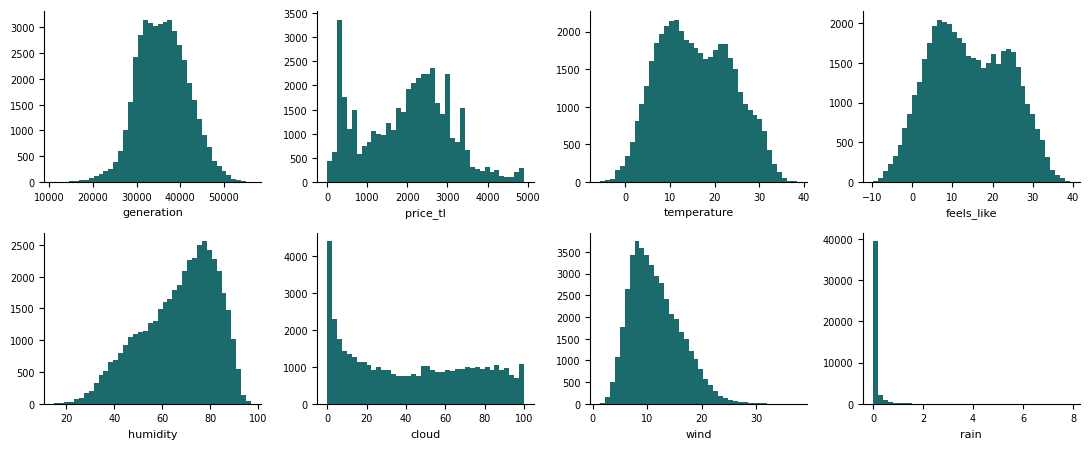

In [11]:
cols = [c for c in NUM if c != TGT][:8]; fig, axes = plt.subplots(2, 4, figsize=(11, 4.6))
for a, c in zip(axes.ravel(), cols):
    x = S[c].dropna().astype(float)
    # x = x.clip(x.quantile(.01), x.quantile(.99))
    a.hist(x, bins=40, color='#1B6B6D'); a.set_xlabel(c, fontsize=8); a.spines[['top', 'right']].set_visible(False); a.tick_params(labelsize=7)
for a in axes.ravel()[len(cols):]: a.axis('off')
fig.tight_layout(); fig.savefig('report/fig_eda_distributions.png', dpi=200); plt.show()

### 2b.7 Giá trị ngoại lai

- **Làm gì:** tỷ lệ dòng nằm ngoài 1,5 lần khoảng tứ phân vị của từng cột.
- **Vì sao:** ngoại lai là lỗi đo thì loại và ghi nhật ký; là hiện tượng thật (đỉnh tải, sự cố) thì giữ và nêu trong bài.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [12]:
N_ = S[NUM].astype(float); q1, q3 = N_.quantile(.25), N_.quantile(.75); iqr = q3 - q1
out = (100 * ((N_ < q1 - 1.5 * iqr) | (N_ > q3 + 1.5 * iqr)).mean()).sort_values(ascending=False).round(2).rename('outside_1.5_IQR_pct')
out.to_csv('report/table_outliers.csv'); display(out.head(12).to_frame())

,outside_1.5_IQR_pct
rain,13.79
holiday,3.78
wind,0.87
generation,0.59
consumption,0.26
humidity,0.17
price_tl,0.00
cloud,0.00
feels_like,0.00
temperature,0.00


### 2b.8 Cột nào liên quan tới mục tiêu

- **Làm gì:** tương quan hạng Spearman giữa từng cột số và mục tiêu, vẽ mười cột mạnh nhất.
- **Vì sao:** đây là dự báo sớm về đặc trưng quan trọng; cột tương quan gần 1 có thể là rò rỉ và phải kiểm tra ý nghĩa.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,0
generation,0.877
humidity,-0.503
hour,0.499
temperature,0.349
feels_like,0.326
price_tl,0.307
weekend,-0.274
wind,0.226
dow,-0.217
holiday,-0.194


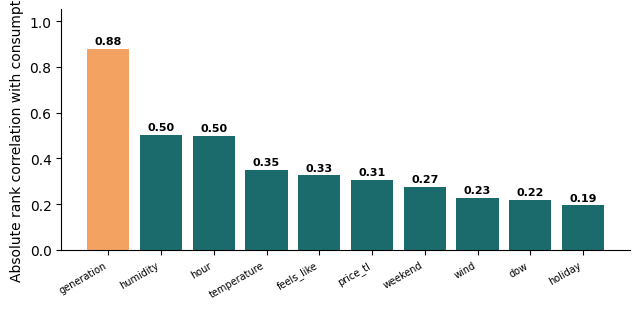

In [13]:
others = [c for c in NUM if c != TGT]
cor = S[others].astype(float).corrwith(S[TGT].astype(float), method='spearman').dropna(); cor = cor.reindex(cor.abs().sort_values(ascending=False).index).head(10)
cor.rename('spearman_with_target').to_csv('report/table_eda_correlation.csv'); display(cor.round(3).to_frame())
if len(cor) and cor.abs().max() > 0: bar_chart(cor.index, cor.abs().values, 'Absolute rank correlation with ' + TGT, 'report/fig_eda_correlation.png', highlight=0, fmt='{:.2f}')

### 2b.9 Các cột mạnh có trùng thông tin không

- **Làm gì:** ma trận tương quan giữa mục tiêu và bảy cột mạnh nhất.
- **Kiểm tra:** hai cột tương quan trên 0,95 với nhau thì chỉ cần giữ một khi giải thích kết quả.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

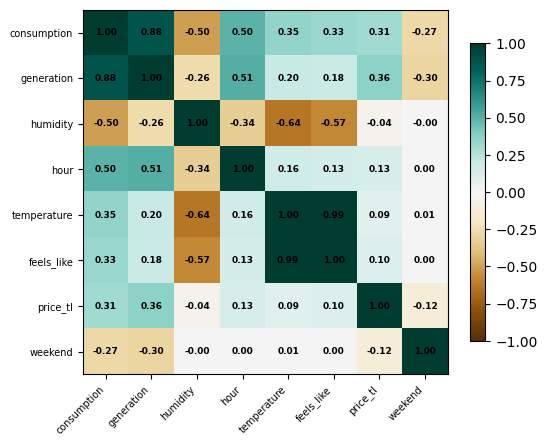

In [14]:
top = [TGT] + list(cor.index[:7]); m = S[top].astype(float).corr(method='spearman'); fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.imshow(m, cmap='BrBG', vmin=-1, vmax=1); ax.set_xticks(range(len(top))); ax.set_yticks(range(len(top))); ax.set_xticklabels(top, rotation=45, ha='right', fontsize=7); ax.set_yticklabels(top, fontsize=7)
for i in range(len(top)):
    for j in range(len(top)): ax.text(j, i, '%.2f' % m.iloc[i, j], ha='center', va='center', fontsize=6.5, fontweight='bold')
fig.colorbar(im, shrink=0.8); fig.tight_layout(); fig.savefig('report/fig_eda_heatmap.png', dpi=200); plt.show()

### 2b.10 Mục tiêu theo nhóm

- **Làm gì:** số dòng, trung bình, trung vị và độ lệch chuẩn của mục tiêu theo cột nhóm, kèm hình.
- **Vì sao:** khác biệt giữa các nhóm là gợi ý trực tiếp cho RQ1 và cho cách chia dữ liệu ở Notebook B.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,rows,mean,median,std
year,,,,
2024,8784,39012.668,39169.780,6494.499
2021,8760,37305.333,37450.710,5672.313
2022,8760,36964.543,37363.075,5557.924
2023,8760,37023.165,37301.010,5928.332
2025,8760,40240.840,40483.620,6568.838


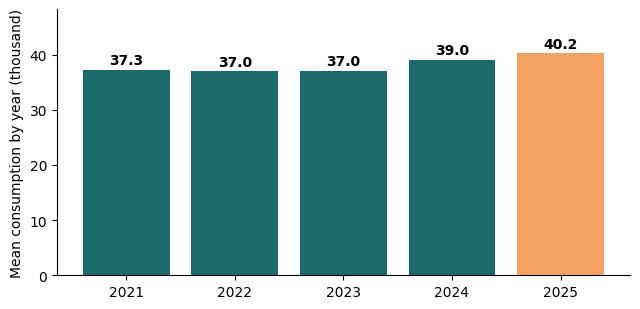

In [15]:
g = E.assign(_t=E[TGT].astype(float)).groupby(GRP)['_t'].agg(['size', 'mean', 'median', 'std']).rename(columns={'size': 'rows'})
g.to_csv('report/table_eda_by_group.csv'); display(g.sort_values('rows', ascending=False).head(15).round(3))
gg = g.sort_values('rows', ascending=False).head(12).sort_index()
if gg['mean'].min() >= 0 and gg['mean'].max() > 0: v, lab, f = nice(gg['mean'], 'Mean ' + TGT + ' by ' + GRP); bar_chart(gg.index.astype(str), v, lab, 'report/fig_eda_by_group.png', highlight=int(v.argmax()), fmt=f)

### Tổng hợp EDA

| Quan sát (có số) | Bằng chứng (bảng, hình) | Ảnh hưởng tới câu hỏi nào | Việc cần làm |
|---|---|---|---|
| | | | |
| | | | |
| | | | |
| | | | |
| | | | |

## Bước 3. Truy vấn dữ liệu bằng SQL

- **Làm gì:** ghi mọi truy vấn vào `sql/queries.sql`, rồi chạy **từng truy vấn một ô** để đọc kết quả và viết nhận xét.
- **Vì sao:** RQ1 được trả lời bằng bảng số; bảng `feat` là đầu vào của Notebook B.
- **Kiểm tra:** tính tay một nhóm nhỏ và so với kết quả truy vấn.

In [16]:
SQL = r"""-- Step 3: sql/queries.sql
CREATE OR REPLACE TABLE el AS SELECT * FROM 'data/processed/electricity.parquet';
-- Q1: mean and peak consumption by year, with growth against the year before (LAG)
SELECT year, AVG(consumption) AS mean_mwh, MAX(consumption) AS peak_mwh, 100.0 * (AVG(consumption) / LAG(AVG(consumption)) OVER (ORDER BY year) - 1) AS growth_pct FROM el GROUP BY 1 ORDER BY 1;
-- Q2: profile of the day on working days, weekends and public holidays
SELECT CASE WHEN holiday = 1 THEN 'holiday' WHEN weekend = 1 THEN 'weekend' ELSE 'working day' END AS day_type, hour, AVG(consumption) AS mean_mwh FROM el GROUP BY 1, 2 ORDER BY 1, 2;
-- Q3: consumption against temperature in bands of 5 degrees: heating on the left, cooling on the right
SELECT FLOOR(temperature / 5) * 5 AS temp_band, COUNT(*) AS hours, AVG(consumption) AS mean_mwh, RANK() OVER (ORDER BY AVG(consumption) DESC) AS rank FROM el GROUP BY 1 HAVING COUNT(*) > 100 ORDER BY 1;
-- Q4: model table; the target is the consumption 24 hours ahead; the calendar of the target hour is known in advance, the weather of the target hour is kept only for the upper-bound test
CREATE OR REPLACE TABLE feat AS
WITH b AS (SELECT time, year, consumption, temperature, humidity, cloud, wind, rain,
             LEAD(consumption, 24) OVER w AS y, LEAD(time, 24) OVER w AS target_time, LEAD(holiday, 24) OVER w AS holiday, LEAD(temperature, 24) OVER w AS temp_at_target,
             LAG(consumption, 1) OVER w AS cons_1h, LAG(consumption, 24) OVER w AS cons_yesterday, LAG(consumption, 144) OVER w AS same_hour_last_week,
             AVG(consumption) OVER (ORDER BY time ROWS BETWEEN 23 PRECEDING AND CURRENT ROW) AS mean_24h, AVG(consumption) OVER (ORDER BY time ROWS BETWEEN 167 PRECEDING AND CURRENT ROW) AS mean_7d,
             AVG(temperature) OVER (ORDER BY time ROWS BETWEEN 23 PRECEDING AND CURRENT ROW) AS temp_mean_24h
      FROM el WINDOW w AS (ORDER BY time))
SELECT *, year(target_time) AS target_year, hour(target_time) AS hour, dayofweek(target_time) AS dow, CASE WHEN dayofweek(target_time) IN (0, 6) THEN 1 ELSE 0 END AS weekend,
       SIN(2 * PI() * dayofyear(target_time) / 365.25) AS season_sin, COS(2 * PI() * dayofyear(target_time) / 365.25) AS season_cos
FROM b WHERE y IS NOT NULL AND same_hour_last_week IS NOT NULL;
SELECT target_year, COUNT(*) AS n, AVG(y) AS mean_target, SUM(holiday) AS holiday_hours FROM feat GROUP BY 1 ORDER BY 1;
"""
open('sql/queries.sql', 'w').write(SQL)

2422

In [17]:
import duckdb
con = duckdb.connect(); QN = 0
def run(stmt):                                           # runs one statement; a SELECT is shown, saved and plotted when the result is small
    global QN
    body = '\n'.join(l for l in stmt.split('\n') if not l.strip().startswith('--')).strip()
    if not body.upper().startswith(('SELECT', 'WITH', 'SUMMARIZE')): con.execute(stmt); print('done'); return None
    QN += 1; r = con.execute(stmt).df(); r.to_csv('report/table_q%d.csv' % QN, index=False); display(r.head(30))
    numc = [c for c in r.columns[1:] if pd.api.types.is_numeric_dtype(r[c])]
    if 2 <= len(r) <= 30 and numc and r[numc[0]].notna().all() and r[numc[0]].min() >= 0 and r[numc[0]].max() > 0:
        v, lab, f = nice(r[numc[0]], numc[0]); bar_chart(r.iloc[:, 0].astype(str), v, lab, 'report/fig_q%d.png' % QN, highlight=int(v.argmax()), fmt=f)
    return r

### Step 3: sql/queries.sql

- **Làm gì:** chạy truy vấn.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

In [18]:
r = run(r"""-- Step 3: sql/queries.sql
CREATE OR REPLACE TABLE el AS SELECT * FROM 'data/processed/electricity.parquet';""")

done


### Q1: mean and peak consumption by year, with growth against the year before (LAG)

- **Làm gì:** chạy truy vấn, xem bảng và hình.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,year,mean_mwh,peak_mwh,growth_pct
0,2021,37305.333148,55575.02,NaN
1,2022,36964.542957,51353.67,-0.913516
2,2023,37023.165500,54044.88,0.158591
3,2024,39012.667674,57772.40,5.373668
4,2025,40240.840247,59503.67,3.148138


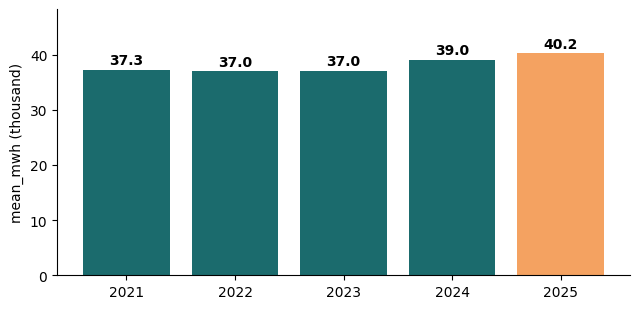

In [19]:
r = run(r"""-- Q1: mean and peak consumption by year, with growth against the year before (LAG)
SELECT year, AVG(consumption) AS mean_mwh, MAX(consumption) AS peak_mwh, 100.0 * (AVG(consumption) / LAG(AVG(consumption)) OVER (ORDER BY year) - 1) AS growth_pct FROM el GROUP BY 1 ORDER BY 1;""")

### Q2: profile of the day on working days, weekends and public holidays

- **Làm gì:** chạy truy vấn, xem bảng và hình.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [20]:
r = run(r"""-- Q2: profile of the day on working days, weekends and public holidays
SELECT CASE WHEN holiday = 1 THEN 'holiday' WHEN weekend = 1 THEN 'weekend' ELSE 'working day' END AS day_type, hour, AVG(consumption) AS mean_mwh FROM el GROUP BY 1, 2 ORDER BY 1, 2;""")

,day_type,hour,mean_mwh
0,holiday,0,31340.030000
1,holiday,1,29653.351304
2,holiday,2,28333.121014
3,holiday,3,27444.900435
4,holiday,4,26950.240000
5,holiday,5,26277.080870
6,holiday,6,25677.920290
7,holiday,7,26401.029855
8,holiday,8,28578.299275
9,holiday,9,30634.859275


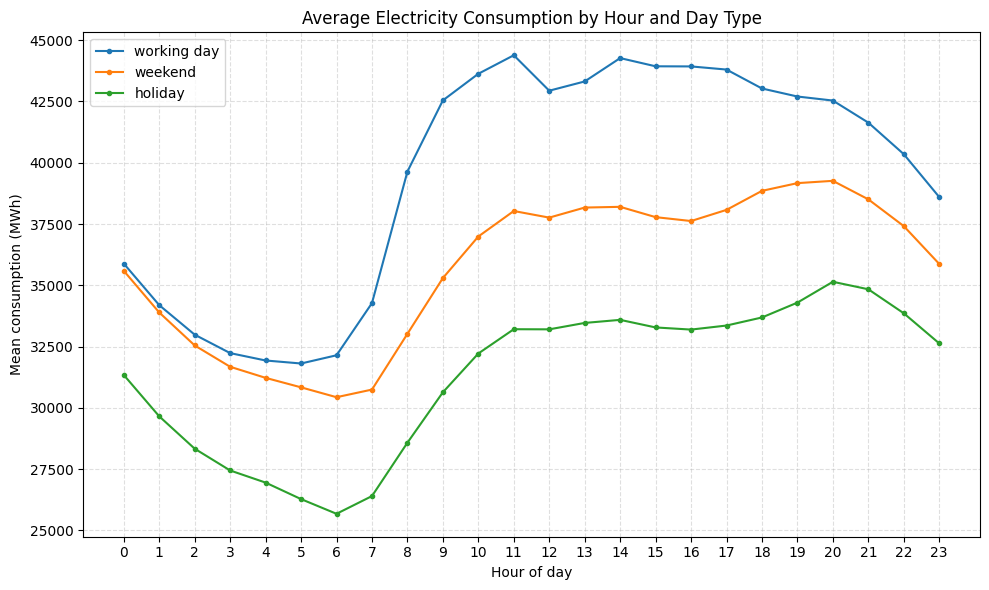

In [21]:
import matplotlib.pyplot as plt

# Chuyển dữ liệu từ dạng dài sang dạng rộng
plot_data = r.pivot(
    index='hour',
    columns='day_type',
    values='mean_mwh'
)

# Vẽ biểu đồ đường
plt.figure(figsize=(10, 6))

for day_type in ['working day', 'weekend', 'holiday']:
    if day_type in plot_data.columns:
        plt.plot(
            plot_data.index,
            plot_data[day_type],
            marker='o',
            markersize=3,
            label=day_type
        )

plt.xlabel('Hour of day')
plt.ylabel('Mean consumption (MWh)')
plt.title('Average Electricity Consumption by Hour and Day Type')
plt.xticks(range(24))
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

### Q3: consumption against temperature in bands of 5 degrees: heating on the left, cooling on the right

- **Làm gì:** chạy truy vấn, xem bảng và hình.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,temp_band,hours,mean_mwh,rank
0,-5.0,497,35266.381066,8
1,0.0,3492,36975.823975,5
2,5.0,8439,37046.612359,4
3,10.0,9084,35961.229795,6
4,15.0,7755,35499.631649,7
5,20.0,7830,38520.775526,3
6,25.0,4664,44183.297646,2
7,30.0,1966,48842.821872,1


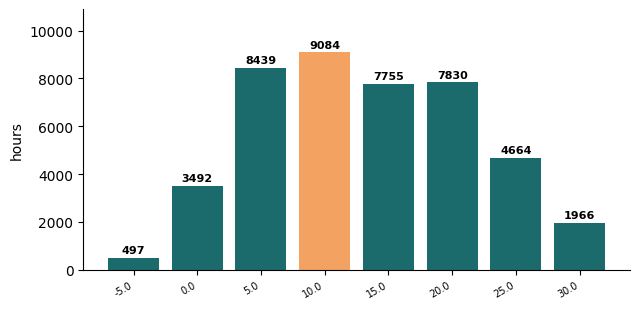

In [22]:
r = run(r"""-- Q3: consumption against temperature in bands of 5 degrees: heating on the left, cooling on the right
SELECT FLOOR(temperature / 5) * 5 AS temp_band, COUNT(*) AS hours, AVG(consumption) AS mean_mwh, RANK() OVER (ORDER BY AVG(consumption) DESC) AS rank FROM el GROUP BY 1 HAVING COUNT(*) > 100 ORDER BY 1;""")

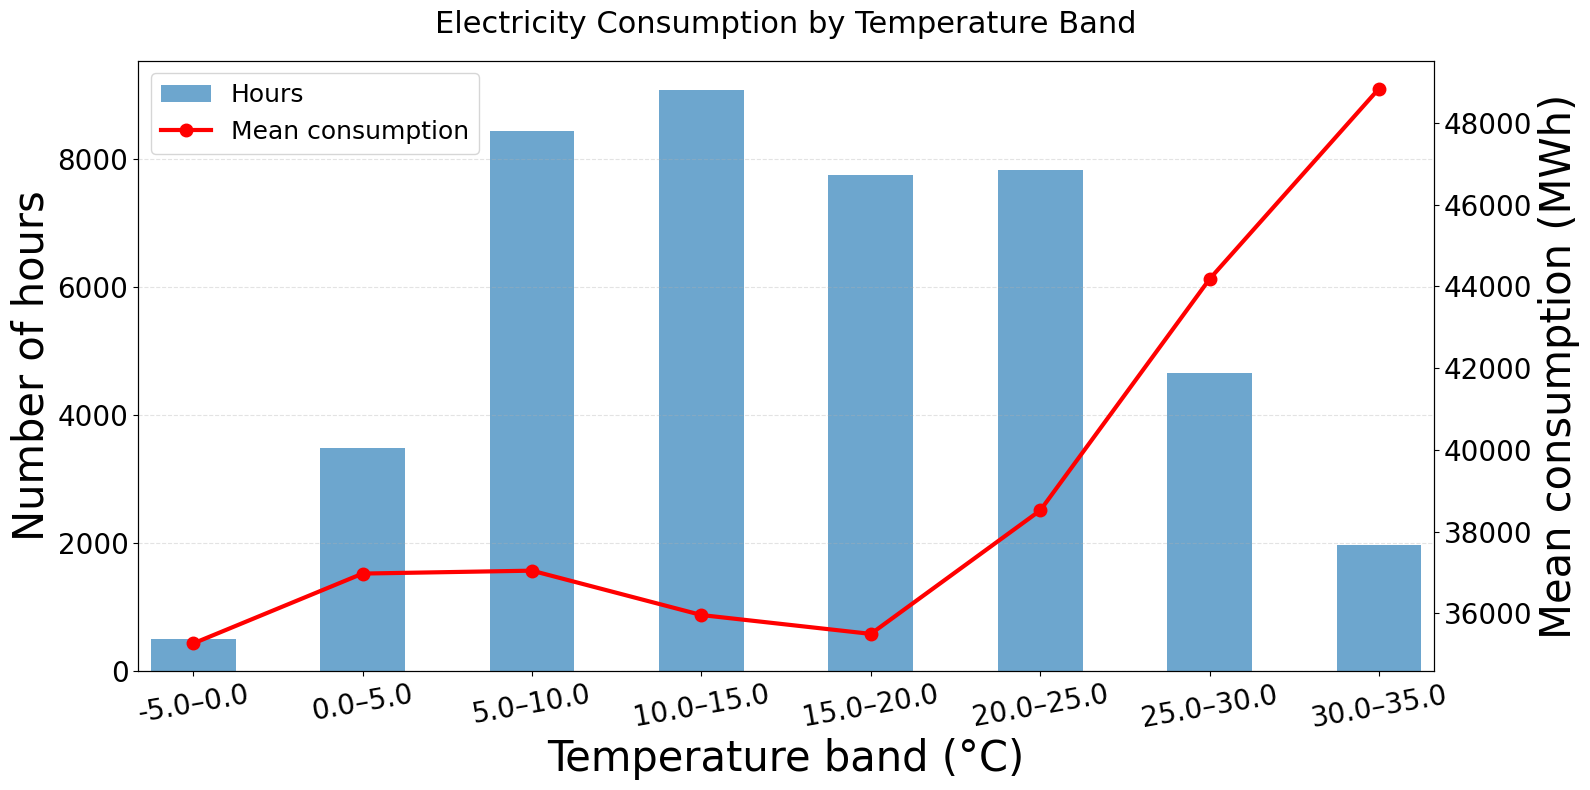

In [23]:
import matplotlib.pyplot as plt

x = r['temp_band']
hours = r['hours']
mean_mwh = r['mean_mwh']

fig, ax1 = plt.subplots(figsize=(16, 8))

# Biểu đồ cột
ax1.bar(x, hours, width=2.5, alpha=0.65, label='Hours')
ax1.set_xlabel('Temperature band (°C)', fontsize=30)
ax1.set_ylabel('Number of hours', fontsize=30)

ax1.set_xticks(x)
ax1.set_xticklabels(
    [f'{t}–{t+5}' for t in x],
    rotation=10,
    ha='center',
    fontsize=20
)
ax1.tick_params(axis='y', labelsize=20)

# Biểu đồ đường
ax2 = ax1.twinx()
ax2.plot(
    x, mean_mwh,
    color='red',
    marker='o',
    markersize=9,
    linewidth=3,
    label='Mean consumption'
)
ax2.set_ylabel('Mean consumption (MWh)', fontsize=30)
ax2.tick_params(axis='y', labelsize=20)

# Tiêu đề
ax1.set_title(
    'Electricity Consumption by Temperature Band',
    fontsize=22,
    pad=20
)

# Chú giải
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    fontsize=18,
    loc='upper left'
)

ax1.grid(axis='y', linestyle='--', alpha=0.35)
ax1.margins(x=0.01)

plt.tight_layout()
plt.show()

### Q4: model table; the target is the consumption 24 hours ahead; the calendar of the target hour is known in advance, the weather of the target hour is kept only for the upper-bound test

- **Làm gì:** chạy truy vấn.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

In [24]:
r = run(r"""-- Q4: model table; the target is the consumption 24 hours ahead; the calendar of the target hour is known in advance, the weather of the target hour is kept only for the upper-bound test
CREATE OR REPLACE TABLE feat AS
WITH b AS (SELECT time, year, consumption, temperature, humidity, cloud, wind, rain,
             LEAD(consumption, 24) OVER w AS y, LEAD(time, 24) OVER w AS target_time, LEAD(holiday, 24) OVER w AS holiday, LEAD(temperature, 24) OVER w AS temp_at_target,
             LAG(consumption, 1) OVER w AS cons_1h, LAG(consumption, 24) OVER w AS cons_yesterday, LAG(consumption, 144) OVER w AS same_hour_last_week,
             AVG(consumption) OVER (ORDER BY time ROWS BETWEEN 23 PRECEDING AND CURRENT ROW) AS mean_24h, AVG(consumption) OVER (ORDER BY time ROWS BETWEEN 167 PRECEDING AND CURRENT ROW) AS mean_7d,
             AVG(temperature) OVER (ORDER BY time ROWS BETWEEN 23 PRECEDING AND CURRENT ROW) AS temp_mean_24h
      FROM el WINDOW w AS (ORDER BY time))
SELECT *, year(target_time) AS target_year, hour(target_time) AS hour, dayofweek(target_time) AS dow, CASE WHEN dayofweek(target_time) IN (0, 6) THEN 1 ELSE 0 END AS weekend,
       SIN(2 * PI() * dayofyear(target_time) / 365.25) AS season_sin, COS(2 * PI() * dayofyear(target_time) / 365.25) AS season_cos
FROM b WHERE y IS NOT NULL AND same_hour_last_week IS NOT NULL;""")

done


### Các dữ liệu trong bảng `feat`

- **Dữ liệu hiện tại:** `time`, `year`, `consumption`, `temperature`, `humidity`, `cloud`, `wind`, `rain`.
- **Nhãn dự đoán:** `y` = mức tiêu thụ điện sau 24 giờ; `target_time` = thời điểm cần dự đoán.
- **Đặc trưng độ trễ:** `cons_1h` (1 giờ trước), `cons_yesterday` (24 giờ trước), `same_hour_last_week` (144 giờ trước, thực tế là 6 ngày nếu dữ liệu theo giờ).
- **Trung bình trượt:** `mean_24h` (tiêu thụ điện trung bình 24 giờ), `mean_7d` (tiêu thụ điện trung bình 7 ngày), `temp_mean_24h` (nhiệt độ trung bình 24 giờ).
- **Lịch tại thời điểm dự đoán:** `target_year`, `hour`, `dow` (thứ trong tuần), `weekend` (cuối tuần), `holiday` (ngày lễ tại thời điểm mục tiêu).
- **Mã hóa mùa:** `season_sin`, `season_cos` biểu diễn chu kỳ trong năm.
- **Thông tin thời tiết tương lai:** `temp_at_target` = nhiệt độ sau 24 giờ, chỉ dùng cho thử nghiệm giới hạn trên (*upper-bound test*), không dùng làm đầu vào dự báo thực tế.

**Lọc dữ liệu:** Loại các dòng không có `y` hoặc `same_hour_last_week`.

### Statement 6

- **Làm gì:** chạy truy vấn, xem bảng và hình.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,target_year,n,mean_target,holiday_hours
0,2021,8592,37375.402153,312.0
1,2022,8760,36964.542957,336.0
2,2023,8760,37023.165500,312.0
3,2024,8784,39012.667674,336.0
4,2025,8760,40240.840247,336.0


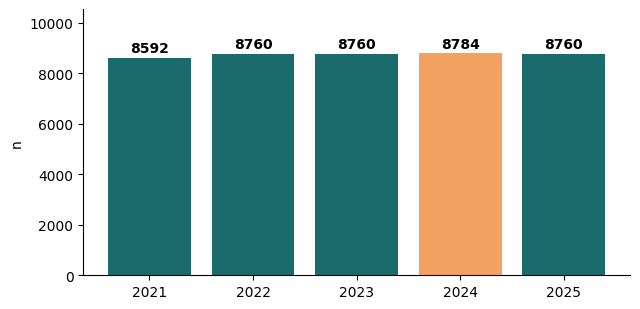

In [25]:
r = run(r"""SELECT target_year, COUNT(*) AS n, AVG(y) AS mean_target, SUM(holiday) AS holiday_hours FROM feat GROUP BY 1 ORDER BY 1;""")

### Truy vấn bổ sung 1: hồ sơ của bảng làm việc

- **Làm gì:** `SUMMARIZE` cho biết min, max, số giá trị khác nhau và tỷ lệ thiếu của mọi cột bằng một lệnh SQL.
- **Kiểm tra:** so với bảng thống kê mô tả ở mục 2b.3.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,column_name,column_type,min,max,approx_unique,null_percentage
0,time,TIMESTAMP_NS,2021-01-01 00:00:00,2025-12-31 23:00:00,39445,0.0
1,consumption,DOUBLE,19209.2,59503.67,50406,0.0
2,generation,DOUBLE,11175.31,56219.06,41331,0.0
3,price_tl,DOUBLE,0.74,4905.5,36729,0.0
4,temperature,DOUBLE,-5.68,38.42,2792,0.0
5,feels_like,DOUBLE,-9.73,39.2,3060,0.0
6,humidity,DOUBLE,14.99,97.09,5303,0.0
7,cloud,DOUBLE,0.0,100.0,7761,0.0
8,wind,DOUBLE,1.36,37.44,2101,0.0
9,rain,DOUBLE,0.0,7.87,342,0.0


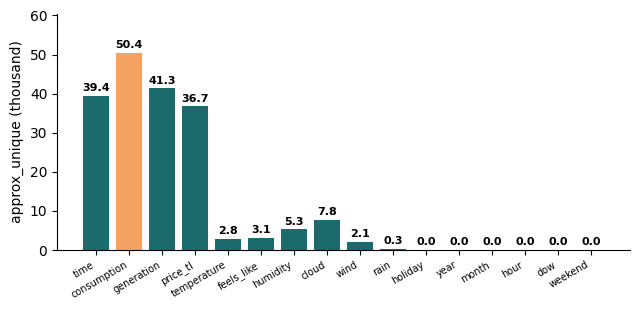

In [26]:
r = run('''SELECT column_name, column_type, min, max, approx_unique, null_percentage FROM (SUMMARIZE el)''')

### Truy vấn bổ sung 2: các phân vị của mục tiêu

- **Làm gì:** phân vị 5%, 25%, 50%, 75%, 95% và 99% của cột mục tiêu.
- **Vì sao:** các phân vị này dùng để chọn ngưỡng, thang trục và cách cắt đuôi khi vẽ.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [27]:
r = run('''SELECT COUNT(*) AS n, MIN("consumption") AS min, QUANTILE_CONT("consumption", 0.05) AS p05, QUANTILE_CONT("consumption", 0.25) AS p25, MEDIAN("consumption") AS p50, QUANTILE_CONT("consumption", 0.75) AS p75, QUANTILE_CONT("consumption", 0.95) AS p95, QUANTILE_CONT("consumption", 0.99) AS p99, MAX("consumption") AS max FROM el''')

,n,min,p05,p25,p50,p75,p95,p99,max
0,43824,19209.2,28840.7665,33159.21,38256.175,42236.9725,48763.261,53430.3265,59503.67


### Truy vấn bổ sung 3: xếp hạng các nhóm

- **Làm gì:** số dòng và trung bình mục tiêu theo nhóm, xếp hạng bằng hàm cửa sổ `RANK`, kèm tỷ trọng của nhóm trong toàn bảng.
- **Vì sao:** nhóm lớn nhất và nhóm lệch nhất thường là ví dụ minh hoạ trong mục Results.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,grp,mean_target,n,pct_of_rows,rank_by_mean
0,2025,40240.840247,8760,19.989047,1
1,2024,39012.667674,8784,20.043812,2
2,2021,37305.333148,8760,19.989047,3
3,2023,37023.165500,8760,19.989047,4
4,2022,36964.542957,8760,19.989047,5


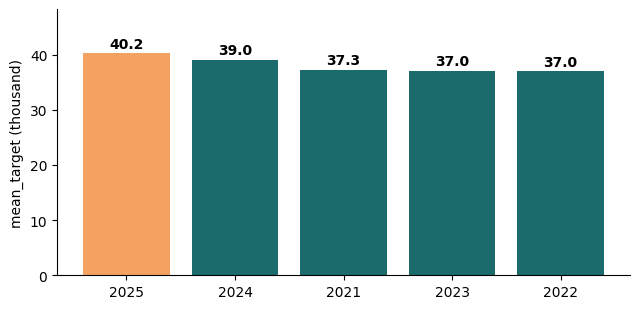

In [28]:
r = run('''SELECT CAST("year" AS VARCHAR) AS grp, AVG("consumption") AS mean_target, COUNT(*) AS n, 100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS pct_of_rows, RANK() OVER (ORDER BY AVG("consumption") DESC) AS rank_by_mean FROM el GROUP BY 1 ORDER BY 5 LIMIT 15''')

### Truy vấn bổ sung 4: bảng mô hình có sạch không

- **Làm gì:** kiểu dữ liệu, tỷ lệ thiếu và số giá trị khác nhau của từng cột trong bảng `feat`.
- **Kiểm tra:** cột đặc trưng nào còn thiếu thì phải xử lý trước khi sang Notebook B.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [29]:
r = run('''SELECT column_name, column_type, null_percentage, approx_unique FROM (SUMMARIZE feat) ORDER BY null_percentage DESC LIMIT 30''')

,column_name,column_type,null_percentage,approx_unique
0,time,TIMESTAMP_NS,0.0,36722
1,year,INTEGER,0.0,5
2,consumption,DOUBLE,0.0,49580
3,temperature,DOUBLE,0.0,2792
4,humidity,DOUBLE,0.0,5303
5,cloud,DOUBLE,0.0,7761
6,wind,DOUBLE,0.0,2101
7,rain,DOUBLE,0.0,342
8,y,DOUBLE,0.0,49580
9,target_time,TIMESTAMP_NS,0.0,36722


## Bước 5. Hình RQ1

- **Làm gì:** vẽ một biểu đồ cột từ kết quả SQL bằng hàm vẽ chuẩn của nhóm.
- **Vì sao:** người đọc phải thấy kết luận của RQ1 trong vài giây.
- **Kiểm tra:** chữ tiếng Anh, không viền trên và phải, số in đậm trên cột, không chữ đè cột. Viết caption nêu kết luận, không mô tả trục.

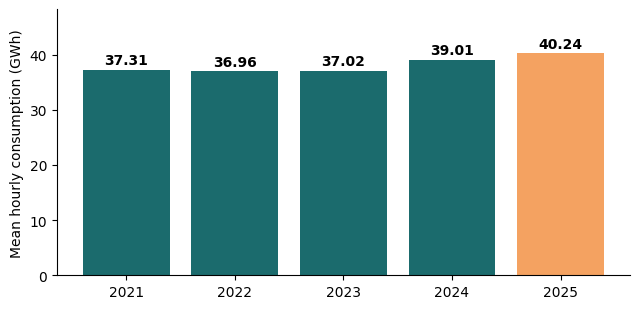

In [30]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

fig1 = con.execute("""SELECT CAST(year AS VARCHAR) AS g, AVG(consumption) / 1000 AS v FROM el GROUP BY year ORDER BY year""").df()
bar_chart(fig1.g, fig1.v, 'Mean hourly consumption (GWh)', 'report/fig_rq1.png', highlight=int(fig1.v.idxmax()), fmt='{:.2f}')

## Bàn giao và test case

- **Làm gì:** ghi `manifest.json` (số dòng, số cột, mã băm) và chạy các kiểm tra tự động.
- **Vì sao:** Notebook B đọc manifest trước khi chạy, nên hai người làm song song mà không lệch dữ liệu.
- **Kiểm tra:** mọi `assert` qua. Sinh viên B chạy lại notebook này trên máy mình và ghi vào ô Đối chứng.

In [31]:
import json, hashlib
path = 'data/processed/electricity.parquet'; t = pd.read_parquet(path)
feat_n = con.execute('SELECT COUNT(*) FROM feat').fetchone()[0]
manifest = {'file': path, 'rows': len(t), 'columns': t.shape[1], 'feat_rows': feat_n,
            'md5': hashlib.md5(open(path, 'rb').read()).hexdigest()}
json.dump(manifest, open('data/processed/manifest.json', 'w'), indent=2); print(manifest)
assert feat_n > 0 and os.path.exists('sql/queries.sql') and os.path.exists('report/table_cleaning_log.csv')
print('Notebook A: all checks passed')

{'file': 'data/processed/electricity.parquet', 'rows': 43824, 'columns': 16, 'feat_rows': 43656, 'md5': '4b34cb7b48fd8fc3151824a94084db61'}
Notebook A: all checks passed


### Đối chứng

| Người chạy lại | Ngày | Số dòng | md5 khớp | Ghi chú |
|---|---|---|---|---|
| | | | | |

### Báo cáo tiến độ (dán vào kênh nhóm trước buổi báo cáo)

1. Việc đã xong, kèm tên file và số dòng, bảng, hình:
2. Con số chính mới có:
3. Vướng mắc và điều đã thử:
4. Việc sẽ làm đến lần báo cáo sau, ai làm:
5. Prompt AI đáng chú ý và Human Delta: